# Оценки, центральная предельная теорема и доверительные интервалы

**Темы:** генеральная совокупность и выборка, точечные оценки и их свойства, доля признака, центральная предельная теорема, стандартная ошибка, доверительные интервалы, метод моментов, метод максимального правдоподобия.

**Идея ноутбука:** создать генеральную совокупность, параметры которой известны заранее, брать из неё выборки и проверять, насколько хорошо по выборкам удаётся восстановить настоящие значения.

## Подготовка

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

---
## 1. Генеральная совокупность и выборка

Генеральная совокупность — все объекты, которые нас интересуют. Обычно её параметры неизвестны, и их оценивают по выборке. Здесь генеральную совокупность мы создадим сами, поэтому сможем сравнить оценки с настоящими значениями.

### 1.1 Генеральные и выборочные характеристики

Создадим генеральную совокупность из 100 000 значений роста, распределённого нормально со средним 170 см и стандартным отклонением 8 см. Посчитаем её генеральное среднее и генеральную дисперсию.

Возьмём из неё случайную выборку объёмом $n = 30$ и посчитаем выборочное среднее, выборочную дисперсию $\sigma^2$ (деление на $n$) и исправленную выборочную дисперсию $S^2$ (деление на $n - 1$). Сравним их с генеральными значениями.

In [2]:
N = 100000
mu = 170
sigma = 8
population = np.random.normal(mu, sigma, N)
pop_mean = population.mean()
pop_var = np.sum((population-pop_mean)**2)/N
# либо сразу же формулой np.var(population) либо population.var()


n = 30
sample = np.random.choice(population, size=n, replace=False) # replace=False каждый человек может попасть в выборку только 1 раз
sample_mean = sample.mean()
sample_var = sample.var()
sample_var_corr = sample.var(ddof=1)


print(f"{'':<25}{'Генеральная':>14}{'Выборка':>12}")
print(f"{'Среднее':<25}{pop_mean:>14.2f}{sample_mean:>12.2f}")
print(f"{'Дисперсия':<25}{pop_var:>14.2f}{sample_var:>12.2f}")
print(f"{'Исправленная дисперсия':<25}{'-----':>14}{sample_var_corr:>12.2f}")


                            Генеральная     Выборка
Среднее                          170.01      171.72
Дисперсия                         64.12       66.12
Исправленная дисперсия            -----       68.40


### 1.2 Несмещённость

Возьмём из генеральной совокупности 10 000 выборок объёмом $n = 5$. Для каждой выборки посчитаем выборочное среднее, выборочную дисперсию $\sigma^2$ и исправленную дисперсию $S^2$.

Усредним каждую из трёх оценок по всем 10 000 выборкам и сравним с генеральным средним и генеральной дисперсией. Определим, какие оценки несмещённые, а какая систематически ошибается и в какую сторону.

In [3]:
n_small = 5
n_samples = 10000
means = []
vars = []
vars_corr = []
for i in range(n_samples):
    sample_small = np.random.choice(population, size=n_small, replace=True) # Так как при значении False NumPy каждый раз перемешивает все 100 000 значений и только потом берёт первые 5
    # это очень долго и для 5 из 100 000 разницы между повторной и бесповторной выборкой практически нет, следовательно ставим True.
    means.append(sample_small.mean())
    vars.append(sample_small.var())
    vars_corr.append(sample_small.var(ddof=1))
    
avg_mean = np.mean(means)
avg_var = np.mean(vars)
avg_var_corr = np.mean(vars_corr)

print(f"{'':<25}{'Генеральная':>15}{'Выборка (30)':>20}{'Выборка (10000 по 5)':>25}")
print(f"{'Среднее':<25}{pop_mean:>15.2f}{sample_mean:>20.2f}{avg_mean:>25.2f}")
print(f"{'Дисперсия':<25}{pop_var:>15.2f}{sample_var:>20.2f}{avg_var:>25.2f}")
print(f"{'Исправленная дисперсия':<25}{'-----':>15}{sample_var_corr:>20.2f}{avg_var_corr:>25.2f}")


                             Генеральная        Выборка (30)     Выборка (10000 по 5)
Среднее                           170.01              171.72                   169.98
Дисперсия                          64.12               66.12                    50.83
Исправленная дисперсия             -----               68.40                    63.53


In [4]:
# Тот же код но через таблицу в Numpy
table = np.random.choice(population, size=(n_samples,n_small), replace=True)
# далее можно рассчитать среднее и дисперсии для каждой строки
table_means = []
table_vars = []
table_vars_corr = []
table_means.append(table.mean(axis=1))
table_vars.append(table.var(axis=1))
table_vars_corr.append(table.var(axis=1, ddof=1))
avg_table_mean = np.mean(table_means)
avg_table_var = np.mean(table_vars)
avg_table_var_corr = np.mean(table_vars_corr)


print(f"{'':<25}{'Генеральная':>15}{'Выборка (30)':>20}{'Выборка (10000 по 5)':>25}")
print(f"{'Среднее':<25}{pop_mean:>15.2f}{sample_mean:>20.2f}{avg_table_mean:>25.2f}")
print(f"{'Дисперсия':<25}{pop_var:>15.2f}{sample_var:>20.2f}{avg_table_var:>25.2f}")
print(f"{'Исправленная дисперсия':<25}{'-----':>15}{sample_var_corr:>20.2f}{avg_table_var_corr:>25.2f}")

                             Генеральная        Выборка (30)     Выборка (10000 по 5)
Среднее                           170.01              171.72                   170.03
Дисперсия                          64.12               66.12                    50.53
Исправленная дисперсия             -----               68.40                    63.16


Повторим тот же эксперимент для $n = 2, 5, 10, 30, 100$ и для каждого $n$ найдём, во сколько раз среднее значение $\sigma^2$ меньше генеральной дисперсии. Сравним это отношение с $\frac{n-1}{n}$.

In [5]:
n_values = [2, 5, 10, 30, 100]

print(f"{'n':>5}{'|':^5}{'avg_var':>10}{'pop_var':>15}{'ratio, %':>15}{'ratio_corr, %':>15}{'theory, %':>15}")
print("-"*7+"|"+"-"*73)
for n in n_values:
    table = np.random.choice(population, size=(n_samples,n), replace=True)
    avg_var = (table.var(axis=1)).mean()
    ratio = 100 - (avg_var/pop_var)*100
    avg_var_corr = (table.var(axis=1, ddof=1)).mean()
    ratio_corr = 100 - (avg_var_corr/pop_var)*100
    print(f"{n:>5}{'|':^5}{avg_var:>10.3f}{pop_var:>15.3f}{ratio:>15.3f}{ratio_corr:>15.3f}{100/n:>15.3f}")
    


    n  |     avg_var        pop_var       ratio, %  ratio_corr, %      theory, %
-------|-------------------------------------------------------------------------
    2  |      32.341         64.115         49.558         -0.883         50.000
    5  |      51.080         64.115         20.331          0.414         20.000
   10  |      57.638         64.115         10.103          0.115         10.000
   30  |      62.108         64.115          3.132         -0.209          3.333
  100  |      63.473         64.115          1.001          0.001          1.000


### 1.3 Состоятельность

Для объёмов выборки $n = 10, 100, 1\,000, 10\,000$ возьмём по одной выборке и посчитаем выборочное среднее. Выведем, насколько каждое из них отличается от генерального среднего.

In [6]:
n_values = [10,100,1000,10000]
print(f"{'n':>5}{'|':^5}{'sample_mean':>15}{'pop_mean':>15}{'diff, см':>15}")
print("-"*7+"|"+"-"*48)
for n in n_values:
    cons_sample = np.random.choice(population, size=n, replace=True)
    cons_mean = cons_sample.mean()
    diff = abs(pop_mean-cons_mean)
    print(f"{n:>5}{'|':^5}{cons_mean:>15.3f}{pop_mean:>15.3f}{diff:>15.3f}")

    n  |      sample_mean       pop_mean       diff, см
-------|------------------------------------------------
   10  |          172.173        170.008          2.165
  100  |          168.848        170.008          1.160
 1000  |          169.851        170.008          0.157
10000  |          170.035        170.008          0.027


Построим график: по оси x — объём выборки $n$ от 1 до 5 000, по оси y — выборочное среднее первых $n$ значений одной большой выборки. Горизонтальной линией отметим генеральное среднее.

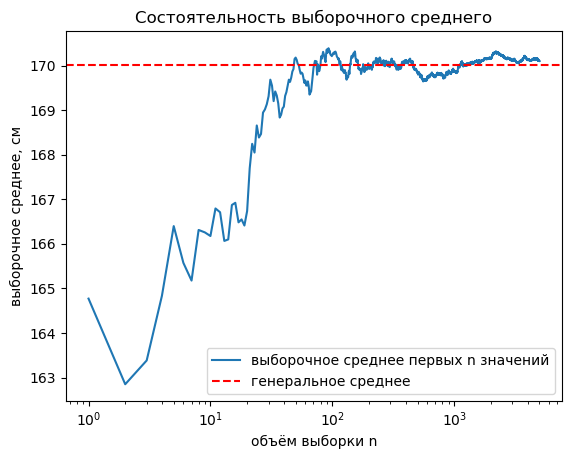

In [7]:
cons_n_max = 5000
cons_means = []
cons_big = np.random.choice(population, size=cons_n_max, replace=True)
for n in range(1, cons_n_max + 1):
    cons_means.append(cons_big[:n].mean())
   
plt.plot(np.arange(1, cons_n_max + 1), cons_means, label="выборочное среднее первых n значений")
plt.axhline(pop_mean, color="red", linestyle="--", label="генеральное среднее")
plt.xlabel("объём выборки n")
plt.ylabel("выборочное среднее, см")
plt.title("Состоятельность выборочного среднего")
plt.legend()
plt.xscale("log")
plt.show()
    
    

**Выводы к разделу 1:**

Если взять из генеральной совокупности одну небольшую выборку, её среднее и дисперсия получаются близкими к настоящим, но каждый раз немного другими — это дело случая.

Чтобы понять, ошибаются ли оценки в какую-то одну сторону, мы взяли 10 000 выборок и посмотрели, что выходит в среднем. Выборочное среднее и исправленная дисперсия попали точно в настоящие значения. А обычная дисперсия (где делим на n) оказалась заниженной. Поэтому по выборке дисперсию считают с делением на n − 1.

На графике видно, что чем больше выборка, тем ближе её среднее к настоящему: сначала оно сильно скачет, а потом успокаивается. Чем больше данных, тем точнее оценка.

---
## 2. Доля признака

Признак типа «да / нет» можно закодировать числами: «да» = 1, «нет» = 0. Тогда среднее таких значений равно доле «да», а дисперсия равна $w(1 - w)$.

### 2.1 Выборочная доля и её дисперсия

Создадим генеральную совокупность из 100 000 клиентов, где каждый с вероятностью $p = 0.27$ согласен купить услугу (1), а иначе не согласен (0). Посчитаем генеральную долю.

Возьмём выборку из 500 клиентов. Найдём выборочную долю $w$ двумя способами: как $\frac{m}{n}$ и как среднее нулей и единиц. Посчитаем дисперсию выборки по обычной формуле (деление на $n$) и сравним её с $w(1 - w)$.

In [8]:
prop_N = 100000
prop_n = 500
prop_p_true = 0.27

prop_population = np.random.binomial(1, prop_p_true, size=prop_N)
prop_p = prop_population.mean()# тут мы посчитали генеральную долю, то, что на самом деле есть в нашей совокупности
# генеральная доля - это как бы псевдо мат ожидание
prop_sample = np.random.choice(prop_population, size=prop_n, replace=True)
prop_m = prop_sample.sum() # количество тех, кто обладает признаком
prop_w_count = prop_m/prop_n # подсчет выборочной доли по формуле w = m/n
prop_w_mean = prop_sample.mean() # подсчет выборочной доли через среднее 0 и 1

prop_var_count = prop_w_count*(1-prop_w_count) # подсчет дисперсии по формуле w(1−w)
prop_var_var = prop_sample.var() # подсчет через обычную дисперсию

print(f"Генеральная доля p:                 {prop_p:.4f}")
print(f"В выборке «да»: {prop_m} из {prop_n}")
print()
print(f"{'':<30}{'способ 1':>12}{'способ 2':>12}")
print(f"{'Выборочная доля w':<30}{prop_w_count:>12.4f}{prop_w_mean:>12.4f}")
print(f"{'Дисперсия доли':<30}{prop_var_count:>12.4f}{prop_var_var:>12.4f}")



Генеральная доля p:                 0.2715
В выборке «да»: 120 из 500

                                  способ 1    способ 2
Выборочная доля w                   0.2400      0.2400
Дисперсия доли                      0.1824      0.1824


Построим график функции $w(1 - w)$ для $w$ от 0 до 1. Отметим, при каком $w$ дисперсия доли максимальна и чему она равна.

Максимум дисперсии доли: w = 0.50, w(1 − w) = 0.25


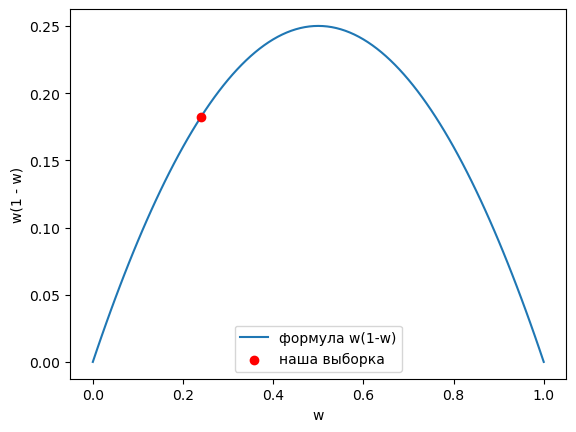

In [9]:
prop_w_grid = np.linspace(0,1,101)
prop_var_grid = prop_w_grid*(1 - prop_w_grid)
print(f"Максимум дисперсии доли: w = {prop_w_grid[np.argmax(prop_var_grid)]:.2f}, w(1 − w) = {prop_var_grid.max():.2f}")
plt.plot(prop_w_grid, prop_var_grid, label="формула w(1-w)" )
plt.xlabel('w')
plt.ylabel('w(1 - w)')
plt.scatter(prop_w_count, prop_var_count, color='red', zorder=5, label="наша выборка")
plt.legend()
plt.show()




**Выводы к разделу 2:**


Создали генеральную совокупность из 100 000 клиентов, где «да» = 1, «нет» = 0, и посчитали генеральную долю. Потом опросили 500 клиентов и нашли выборочную долю. Она получилась немного меньше генеральной — это обычный случайный промах выборки, с другими 500 клиентами она могла бы выйти и больше.

Долю посчитали двумя способами: как m / n и как среднее нулей и единиц — результат совпал. Дисперсию тоже двумя способами: обычной формулой и как w(1 − w) — тоже совпало. То есть для признака «да/нет» среднее — это доля, а дисперсия — произведение доли «да» на долю «нет».

На графике w(1 − w) видно, что дисперсия максимальна при w = 0.5 и равна 0.25: разброс самый большой, когда «да» и «нет» поровну. А при w = 0 или w = 1, когда все ответили одинаково, разброса нет вообще.